In [1]:
#Very first step is to import these modules and libraries into the satprocessing kernel
import numpy as np
import dask as ds
import earthaccess as ea
import xarray as xr
import sys
import matplotlib.pyplot as plt
import requests
import pandas as pd
import PyCO2SYS as pyco2
import cartopy
from shapely.ops import unary_union
import cartopy.feature as cfeature
from datetime import date
from scipy.spatial import KDTree
from datasets import Dataset
print("module import success")

import sys
sys.path.append(r'C:\\Users\\edmund.gable\\Documents\\Hollings_2026\\RESOURCES\\python\\utilities\\bootstrap\\')
print("path import success")

import pprint
from environment import bootstrap_environment  
pprint.pprint(bootstrap_environment(preferred="edmund_gable"))
print("success")

from utilities.bootstrap.environment import bootstrap_environment
env = bootstrap_environment(preferred="edmund.gable")
env
print("utilities import success")

#Before this next step, install the library 'resource': conda install -c conda-forge resource
from utilities import get_dates, get_source_file_dates, find_text
find_text("stats")

from utilities import get_prod_files 
get_prod_files("DO", period="DOY")
#"DOY" is climatological 'day of year
#'W' is climatological weekly files

from pathlib import Path

root = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026")
raw_data = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data")
model_data = Path(r"Z:\\MOM6\Hindcasts\\BTM-O2-REGRID")
processed_data=Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison")




c:\Users\edmund.gable\.conda\envs\satprocessing\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


module import success
path import success
⚠ Unrecognized preferred label 'edmund_gable'. Valid options: ['NECMAC04363461.local', 'nefscsatdata', 'guihyde', 'Mac.localdomain', 'gdavis', 'egable']
{'dataset_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/DATASETS'),
 'hostname': 'NECL04363598',
 'lookuptable_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/lookuptables'),
 'metadata_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/metadata'),
 'project_root': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'python_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'satlogs_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/logs/satprocessing'),
 'timestamp': datetime.datetime(2026, 6, 12, 14, 50, 6, 751174),
 'utilities_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RES

In [ ]:
#!pip install datasets

  Using cached datasets-5.0.0-py3-none-any.whl.metadata (23 kB)
  Using cached filelock-3.29.3-py3-none-any.whl.metadata (2.0 kB)
  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached xxhash-3.7.0-cp313-cp313-win_amd64.whl.metadata (13 kB)
  Using cached multiprocess-0.70.19-py313-none-any.whl.metadata (7.5 kB)
  Using cached huggingface_hub-1.19.0-py3-none-any.whl.metadata (14 kB)
  Using cached anyio-4.13.0-py3-none-any.whl.metadata (4.5 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached click-8.4.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.5.1-cp37-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached typer-0.25.1-py3-none-any.whl.metadata (15 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached a

In [2]:
#create the MOM6-COBALT grid df
df_mom6_raw=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\MOM6_COBALT\2004_01_01.csv")
grid_extent = df_mom6_raw[["lat", "lon"]].drop_duplicates().reset_index(drop=True)

# 3. Create a unique integer ID for every single unique grid cell
grid_extent["grid_id"] = grid_extent.index + 1  # 1-indexed IDs

# 4. Save this file so you don't have to keep rebuilding it
export_path=(r"C:\\Users\\edmund.gable\\Documents\\Hollings_2026\\GitHub\\MOM6-COBALT_2026\\data\\Index\\MOM6_Grid_Extent.csv")
#grid_extent.to_csv(export_path, date_format='%Y-%m-%d %H:%M:%S', index=False)


print(f"Grid extent file created with {len(grid_extent)} unique grid IDs.")
print(grid_extent.head())

dsg=grid_extent.set_index(['lat','lon']).to_xarray()
dsg

Grid extent file created with 159005 unique grid IDs.
         lat        lon  grid_id
0  22.525518 -82.468483        1
1  22.525518 -82.387807        2
2  22.525518 -82.307132        3
3  22.525518 -82.226456        4
4  22.525518 -82.145780        5


<xarray.Dataset> Size: 1MB
Dimensions:  (lat: 413, lon: 385)
Coordinates:
  * lat      (lat) float64 3kB 22.53 22.59 22.65 22.71 ... 48.25 48.31 48.37
  * lon      (lon) float64 3kB -82.47 -82.39 -82.31 ... -51.65 -51.57 -51.49
Data variables:
    grid_id  (lat, lon) int64 1MB 1 2 3 4 5 ... 159002 159003 159004 159005

Text(0.5, 1.0, 'MOM6 Bottom Dissolved Oxygen\n2004-01-01 12:00:00')

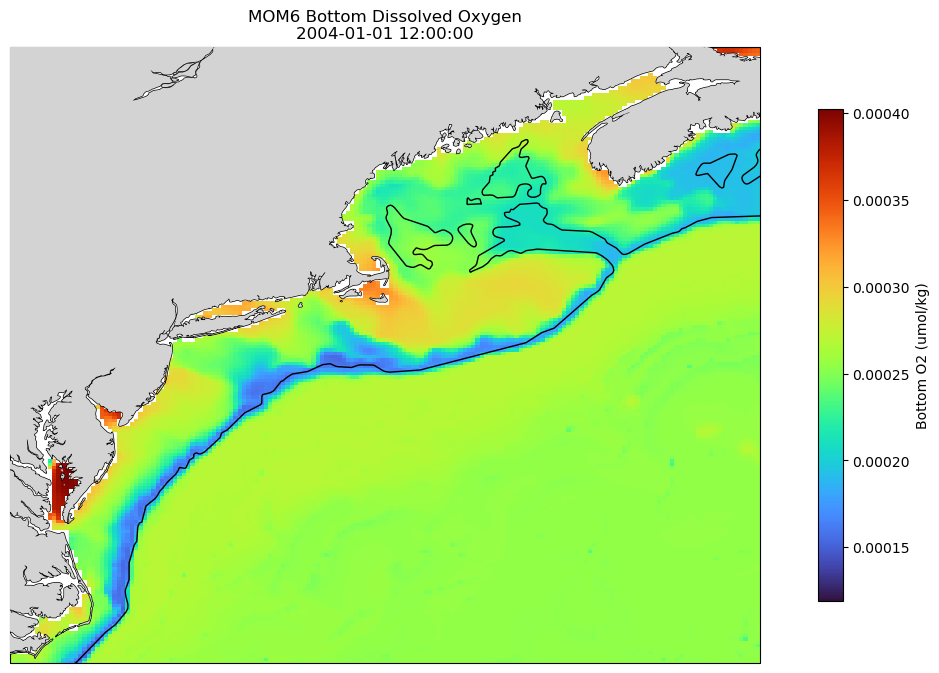

In [3]:
ds=xr.open_dataset(r"Z:\MOM6\Hindcasts\BTM-O2-REGRID\2004\01\CEFI-BTM_O2-HINDCAST-20040101.nc")

bathym = cfeature.NaturalEarthFeature(name='bathymetry_K_200', scale='10m', category='physical')
bathym = unary_union(list(bathym.geometries()))

fig = plt.figure(figsize=(15, 8)) #set figure size
map_projection = cartopy.crs.PlateCarree() #set map projection
ax = plt.axes(projection=map_projection) #link projection to axes
im = plt.pcolormesh(ds.lon,ds.lat,ds.btm_o2[0],cmap='turbo') #what to plot
cb=plt.colorbar(im,shrink=0.8,label='Bottom O2 (umol/kg)') #how big+what to label color bar
ax.add_feature(cartopy.feature.COASTLINE, linewidth=1) #add coastlines
ax.add_feature(cartopy.feature.LAND, zorder=100, facecolor='lightgrey') #add land mask 
ax.add_geometries(bathym, facecolor='none', edgecolor='black', crs=cartopy.crs.PlateCarree()) #add bathymetry line
ax.set_extent([-77, -63, 34.5, 46])
ax.set_title(f'MOM6 Bottom Dissolved Oxygen\n{pd.to_datetime(ds.time[0].values)}')

In [ ]:
def classify_DO(df, DO_column, battery_col=None):
  clean_df=df[df[DO_column]>0].copy()
  classified_df = clean_df.copy()

  classified_df.loc[classified_df[DO_column] >= 3.9, 'DO_status'] = 'Low Oxygen'
  classified_df.loc[classified_df[DO_column] > 5.0, 'DO_status'] = 'Oxygenated' 
  classified_df.loc[classified_df[DO_column] < 3.9, 'DO_status'] = 'Mildly Hypoxic'
  classified_df.loc[classified_df[DO_column] < 2.41, 'DO_status'] = 'Hypoxia'
  classified_df.loc[classified_df[DO_column] < 0.2, 'DO_status'] = 'Anoxia'

    
  # 2. FILTER BATTERY (Only if a battery column name was provided)
  if battery_col is not None:
    classified_df = classified_df[classified_df[battery_col] >= 50]
        
    classified_df = classified_df.reset_index(drop=True)
    
  return classified_df
  
def open_file(file):
  ds=xr.open_dataset(file)
  df=ds.to_dataframe()
  print(df.columns.to_list())
  return df

def check_units(ds, DO_col):
  print(ds[DO_col].attrs)  

In [ ]:
def prepare_df(df, DO_col, id_col, obs_depth_col, bottom_depth_col, lat_col, lon_col, time_col, mom6_grid_df, battery_col=None):
  
  # drop values that are nan
  df=df.dropna(subset=[DO_col])


  # make sure measurement is at bottom
  depth_mismatch = abs(df[obs_depth_col] - df[bottom_depth_col])
  depth_mismatch=depth_mismatch.astype(float)

  max_mismatch=np.minimum(0.1*df[bottom_depth_col], 20)
  df_filtered=df[depth_mismatch<max_mismatch].copy()

  # match to MOM6 grid timestamp
  df_filtered["matched_time"] = pd.to_datetime(df_filtered[time_col]).dt.normalize() + pd.Timedelta(hours=12)
 
  # match to spatial grids
  pt_lats = xr.DataArray(df_filtered[lat_col], dims='points')
  pt_lons = xr.DataArray(df_filtered[lon_col], dims='points')

  # Query the existing dataset directly for the nearest coordinates
  nearest_grid = dsg.sel(lat=pt_lats, lon=pt_lons, method='nearest')

  # Assign those exact grid coordinates back to the dataframe
  #df_filtered['grid_lat'] = nearest_grid.lat.values
  #df_filtered['grid_lon'] = nearest_grid.lon.values
  df_filtered['matched_lat'] = nearest_grid.lat.values
  df_filtered['matched_lon'] = nearest_grid.lon.values
  df_filtered['grid_id'] = nearest_grid.grid_id.values
  df=df_filtered

  rename_dict = {
        DO_col: "dissolved_oxygen",
        id_col: "id",
        obs_depth_col: "obs_depth",
        bottom_depth_col: "bottom_depth",
        lat_col: "lat",
        lon_col: "lon",
        time_col: "time",
    }
  df = df.rename(columns=rename_dict)
  #take everything in one grid cell of point data and average it
  agg_rules = {
        "dissolved_oxygen": "mean",    # Average the oxygen measurements in the cell
        "obs_depth": "mean",           # Average the depths they were taken at
        "bottom_depth": "mean",        # Average the seafloor depths
        "lat": "mean",                 # Average the exact vessel latitudes
        "lon": "mean",                 # Average the exact vessel longitudes
        "id": "first",                 # Keep the cruise/vessel ID 
        #"time": "first",               # DON'T Keep the original raw timestamp
        "matched_lat": "first",        # Grid lats are identical for this group, keep first
        "matched_lon": "first"         # Grid lons are identical for this group, keep first
    }
    
#Group by the day and grid cell, apply rules, and restore flat dataframe structure
  df = df.groupby(['matched_time', 'grid_id']).agg(agg_rules).reset_index()
  df=classify_DO(df, DO_col, battery_col=battery_col)
  requested_columns = [
        "id",
        "lat",
        "lon",
        "obs_depth",
        "bottom_depth",
        "dissolved_oxygen",
        "DO_status",  
        "grid_id",
        "matched_time",
        "matched_lat",
        "matched_lon"
        ]

 
  return df[requested_columns]

In [4]:
file=(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\Hydrographic_Monitoring\errdap_search.nc")
df=open_file(file)

check_units(df, 'dissolved_oxygen')
df=df[df['cruise_id']!='HB2101']
classified_df=classify_DO(df, 'dissolved_oxygen')
mom6_grid_df=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Index\MOM6_Grid_Extent.csv")

dfp=prepare_df(df, 'dissolved_oxygen', 'cruise_id', 'depth', 'bottom_depth', 'latitude', 'longitude', 'UTC_DATETIME', mom6_grid_df)
dfp
#dfp.to_csv(processed_data / "Hydrographic_Monitoring_matched_2009_2025.csv")

NameError: name 'open_file' is not defined

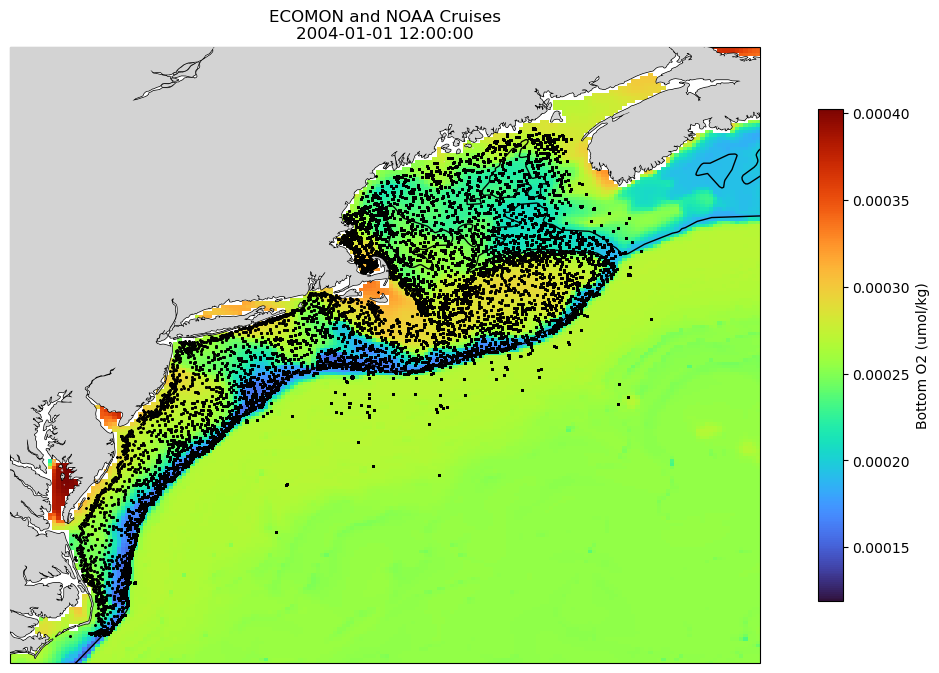

In [31]:
bathym = cfeature.NaturalEarthFeature(name='bathymetry_K_200', scale='10m', category='physical')
bathym = unary_union(list(bathym.geometries()))

fig = plt.figure(figsize=(15, 8)) #set figure size
map_projection = cartopy.crs.PlateCarree() #set map projection
ax = plt.axes(projection=map_projection) #link projection to axes
im = plt.pcolormesh(ds.lon,ds.lat,ds.btm_o2[0],cmap='turbo') #what to plot
cb=plt.colorbar(im,shrink=0.8,label='Bottom O2 (umol/kg)') #how big+what to label color bar
ax.add_feature(cartopy.feature.COASTLINE, linewidth=1) #add coastlines
ax.add_feature(cartopy.feature.LAND, zorder=100, facecolor='lightgrey') #add land mask 
ax.add_geometries(bathym, facecolor='none', edgecolor='black', crs=cartopy.crs.PlateCarree()) #add bathymetry line
ax.set_extent([-77, -63, 34.5, 46])
ax.set_title(f'ECOMON and NOAA Cruises\n{pd.to_datetime(ds.time[0].values)}')
plt.scatter(df.longitude.astype(float), df.latitude.astype(float), c='black', s=0.1)

In [ ]:

def load_matching_mom6_data(df, model_data):
    # 1. Change this to a list to hold daily dataframes
    df_list = []

    # Get the list of unique datetimes from observational data
    unique_dates = pd.to_datetime(df['matched_time']).dt.normalize().unique()

    print(f"Found {len(unique_dates)} unique dates to query")

    for date in unique_dates:
        year = str(date.year)
        month = f"{date.month:02d}"
        day = f"{date.day:02d}"
        
        # Match the exact filename structure
        file_name = f"CEFI-BTM_O2-HINDCAST-{year}{month}{day}.nc"
        target_file_path = model_data / year / month / file_name

        # Filter the cruise dataframe down to just the points needed for this specific day
        current_date_str = f"{year}-{month}-{day}"
        df_day = df[pd.to_datetime(df['matched_time']).dt.normalize() == date]
        
        # Check if the file exists before attempting to open it
        if target_file_path.exists():
            print(f"Extracting data for {year}-{month}-{day}...")
            
            # Open the dataset
            ds = xr.open_dataset(target_file_path)
            
            # 2. Extract ONLY the bottom oxygen variable to keep memory footprint low
            # CRITICAL: Replace 'o2_bottom' with the exact name of the variable inside your netCDF file!
            o2_slice = ds['btm_o2'] 
            
            # 3. Convert this specific spatial grid slice into a flat pandas DataFrame
            daily_df = o2_slice.to_dataframe().reset_index()
            
            # Keep only the columns you care about
            # Note: Depending on your NetCDF setup, 'time' might automatically be included
            keep_cols = ['lat', 'lon', 'btm_o2'] 
            daily_df = daily_df[[c for c in daily_df.columns if c in keep_cols or c == 'time']]
            
            # Explicitly track which date this grid belongs to
            daily_df['matched_time'] = pd.to_datetime(f"{year}-{month}-{day}")
            
            # Append this day's table to our master list
            df_list.append(daily_df)
            
            # Close the dataset file connection safely
            ds.close()
        else:
            print(f"⚠️ Warning: Model file not found for {year}-{month}-{day} at: {target_file_path}")
            
    # 4. Concatenate all individual daily dataframes into one single, master DataFrame
    if df_list:
        final_model_df = pd.concat(df_list, ignore_index=True)
        return final_model_df
    else:
        print(" No matching model files were found or loaded.")
        return pd.DataFrame() # Return empty dataframe as fallback

In [ ]:

def load_matching_mom6_data(df, model_data):

    df_list = []

    # Get the list of unique datetimes from observational data
    unique_dates = pd.to_datetime(df['matched_time']).dt.normalize().unique()

    print(f"Found {len(unique_dates)} unique dates to query")


    for date in unique_dates:
        year = str(date.year)
        month = f"{date.month:02d}"
        day = f"{date.day:02d}"
        
        # Match the exact filename structure
        file_name = f"CEFI-BTM_O2-HINDCAST-{year}{month}{day}.nc"
        target_file_path = model_data / year / month / file_name
        
        # Filter the cruise dataframe down to just the points needed for this specific day
        current_date_str = f"{year}-{month}-{day}"
        df_day = df[pd.to_datetime(df['matched_time']).dt.normalize() == date]
        
        # Check if the file exists before attempting to open it
        if target_file_path.exists():
            print(f"Extracting data for {current_date_str}...")
            
            # Open the dataset
            ds = xr.open_dataset(target_file_path)
            
            # Extract ONLY the bottom oxygen variable
            o2_slice = ds['btm_o2'] 
            
            #  Target only the specific grid IDs present on this day ---
            for _, row in df_day.iterrows():
              try:
                    # --- FIXED SPATIAL LOOKUP ---
                    # Use coordinate matching (.sel) instead of positional indexing (.isel)
                    # This searches the grid using the target latitude and longitude directly
                    model_val = o2_slice.sel(
                        lat=row['matched_lat'], 
                        lon=row['matched_lon'], 
                        method='nearest'
                    ).values
                    
                    # Safely convert the resulting numpy array/scalar into a standard float
                    btm_o2_val = float(np.atleast_1d(model_val)[0])
              except Exception as e:
                    print(f" Lookup failed for Lat {row['matched_lat']}, Lon {row['matched_lon']}: {e}")
                    btm_o2_val = np.nan

                
                # Build a single clean row combining the cruise data with the model value
              matched_row = row.to_dict()
              matched_row['btm_o2'] = btm_o2_val
              df_list.append(matched_row)
            
            # Close the dataset file connection safely
            ds.close()
        else:
            print(f"⚠️ Model file not found for {year}-{month}-{day} at: {target_file_path}")
            # If the file is missing, still retain the cruise data rows but fill model data with NaN
            for _, row in df_day.iterrows():
                matched_row = row.to_dict()
                matched_row['btm_o2'] = np.nan
                df_list.append(matched_row)

    # 4. Convert all individual rows into one single, master DataFrame
    if df_list:
        final_model_df = pd.DataFrame(df_list)
        return final_model_df
    else:
        print("No matching model files were found or loaded.")
        return pd.DataFrame() # Return empty dataframe as fallback

In [6]:
ds=xr.open_dataset(r"Z:\MOM6\Hindcasts\BTM-O2-REGRID\2004\01\CEFI-BTM_O2-HINDCAST-20040101.nc")
df=ds.to_dataframe()
df=df.reset_index()
print(df.columns.to_list())


['time', 'lat', 'lon', 'btm_o2']


In [7]:
df=pd.read_csv(processed_data / "Hydrographic_Monitoring_matched_2009_2025.csv")
loaded_datasets= load_matching_mom6_data(df, model_data)
loaded_datasets.to_csv(processed_data / "ECOMON_MOM6_comparison.csv")

Found 1232 unique dates to query
Extracting data for 2009-08-18...
Extracting data for 2009-08-19...
Extracting data for 2009-08-20...
Extracting data for 2009-08-21...
Extracting data for 2009-08-22...
Extracting data for 2009-08-23...
Extracting data for 2009-08-24...
Extracting data for 2009-08-25...
Extracting data for 2009-08-26...
Extracting data for 2009-08-27...
Extracting data for 2009-08-28...
Extracting data for 2009-11-03...
Extracting data for 2009-11-04...
Extracting data for 2009-11-05...
Extracting data for 2009-11-07...
Extracting data for 2009-11-08...
Extracting data for 2009-11-09...
Extracting data for 2009-11-10...
Extracting data for 2009-11-11...
Extracting data for 2009-11-17...
Extracting data for 2009-11-18...
Extracting data for 2009-11-19...
Extracting data for 2010-02-03...
Extracting data for 2010-02-04...
Extracting data for 2010-02-09...
Extracting data for 2010-02-10...
Extracting data for 2010-02-12...
Extracting data for 2010-02-13...
Extracting data

In [ ]:
loaded_datasets.to_csv(processed_data / "ECOMON_MOM6_comparison.csv")

In [ ]:
ds=xr.open_dataset(r"Z:\MOM6\Hindcasts\BTM-O2-REGRID\2004\01\CEFI-BTM_O2-HINDCAST-20040101.nc")
df=ds.to_dataframe()
print(df.columns.to_list())
df

['btm_o2']


In [31]:
def delta_difference(df):
    df['bottom_o2_mgL']=df['btm_o2']*31998*1.025
    df['delta_difference']=df['bottom_o2_mgL']-df['dissolved_oxygen']
    print(f'mean of delta difference between observational data and model data is {df['delta_difference'].mean}')
    return df


In [ ]:
output=delta_difference(loaded_datasets)
output.to_csv(processed_data / "ECOMON_MOM6_comparison.csv")
output

mean of delta difference between observational data and model data is <bound method Series.mean of 0       2.077795
1       3.294636
2       3.067808
3       0.009071
4       3.469272
          ...   
5346         NaN
5347         NaN
5348         NaN
5349         NaN
5350         NaN
Name: delta_difference, Length: 5351, dtype: float64>


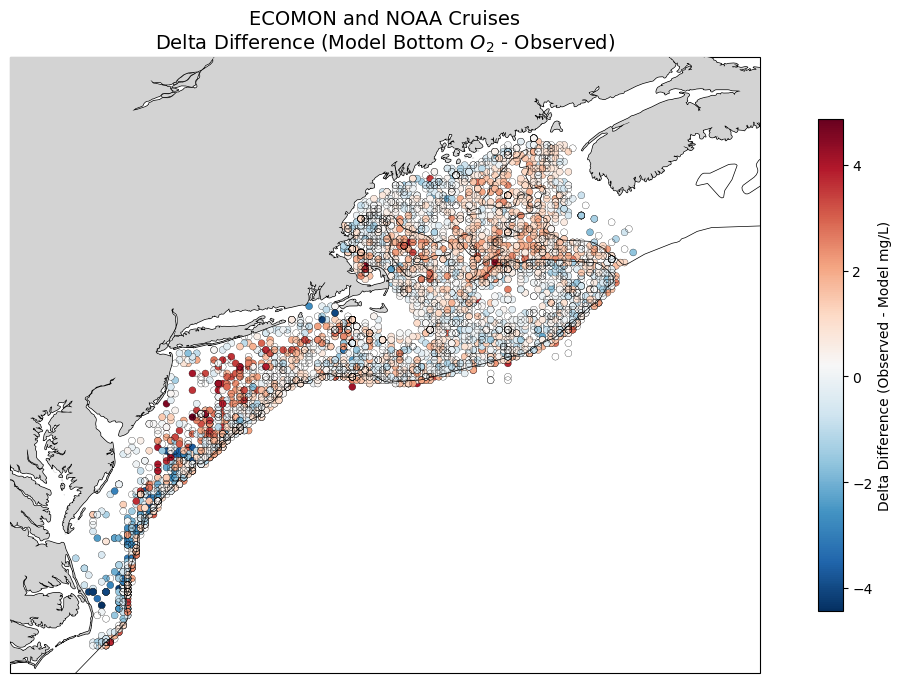

In [37]:
bathym = cfeature.NaturalEarthFeature(name='bathymetry_K_200', scale='10m', category='physical')
bathym = unary_union(list(bathym.geometries()))

fig = plt.figure(figsize=(15, 8)) #set figure size
map_projection = cartopy.crs.PlateCarree() #set map projection
ax = plt.axes(projection=map_projection) #link projection to axes
sc=ax.scatter(output['matched_lon'].astype(float), output['matched_lat'].astype(float), c=output['delta_difference'], cmap='RdBu_r', s=25, edgecolors='black', linewidths=0.2, transform=cartopy.crs.PlateCarree())

cb = plt.colorbar(sc, shrink=0.8, label='Delta Difference (Observed - Model mg/L)')

# Optional: Center the colorbar around 0 if you want to balance over/underestimation
# import matplotlib.colors as mcolors
# sc.set_norm(mcolors.TwoSlopeNorm(vcenter=0))

# 5. Add map layers and features
ax.add_feature(cfeature.COASTLINE, linewidth=1)
ax.add_feature(cfeature.LAND, zorder=100, facecolor='lightgrey')
ax.add_geometries(bathym, facecolor='none', edgecolor='black', linewidth=0.5, crs=cartopy.crs.PlateCarree())

# 6. Set map spatial limits (Mid-Atlantic Bight / New England shelf)
ax.set_extent([-77, -63, 34.5, 46])

# 7. Add text decoration
ax.set_title('ECOMON and NOAA Cruises\nDelta Difference (Model Bottom $O_2$ - Observed)', fontsize=14)

plt.show()

Discontinued Code:

In [ ]:
def prepare_df(df, DO_col, id_col, obs_depth_col, bottom_depth_col, lat_col, lon_col, time_col, mom6_grid_df, battery_col=None):
  #drop values that are nan
  df=df.dropna(subset=[DO_col])
  #classify the oxygen level
  df_working=classify_DO(df, DO_col, battery_col=None)
  #make sure measurement is at bottom
  depth_mismatch = abs(df_working[obs_depth_col] - df_working[bottom_depth_col])
  df_filtered=df_working[depth_mismatch<10].copy()
  #match to MOM6 grid timestamp
  df_filtered["matched_time"] = pd.to_datetime(df_filtered[time_col]).dt.normalize() + pd.Timedelta(hours=12)
 
  #match to spatial grids
  pt_lats = xr.DataArray(df[lat_col], dims='points')
  pt_lons = xr.DataArray(df[lon_col], dims='points')

  # Query your existing dataset directly for the nearest coordinates
  nearest_grid = dsg.sel(lat=pt_lats, lon=pt_lons, method='nearest')

  # Assign those exact grid coordinates back to your dataframe
  df['grid_lat'] = nearest_grid.lat.values
  df['grid_lon'] = nearest_grid.lon.values

  df_filtered['matched_lat']=matched_lat_lon[:, 0]
  df_filtered['matched_lon']=matched_lat_lon[:, 1]
  return df_filtered


In [ ]:

def load_matching_mom6_data(df, model_data):
    loaded_datasets={}

    #get the list of unique datetimes from observational data
    unique_dates=pd.to_datetime(df['matched_time']).dt.normalize().unique()

    print(f"found {len(unique_dates)} unique dates to query")

    for date in unique_dates:
    # 2. Format year, month, and day components
      year = str(date.year)
      month = f"{date.month:02d}"
      day = f"{date.day:02d}"
        
     # 3. Match the exact filename structure: CEFI-BTM_O2-HINDCAST-YYYYMMDD.nc
      file_name = f"CEFI-BTM_O2-HINDCAST-{year}{month}{day}.nc"
        
      # Build the path: Base/Year/Month/Filename
      #         # (Note: Based on your path, there isn't a separate folder for Day, just Year and Month)
      target_file_path = model_data / year / month / file_name
        
      # 4. Check if the file exists before attempting to open it
      if target_file_path.exists():
            print(f"Loading data for {year}-{month}-{day}...")
            # Open the dataset with chunks for memory-efficient lazy loading
            ds = xr.open_dataset(target_file_path, chunks={'time': 1})
            
            # Store it in our dictionary using the date string as the key
            date_key = date.strftime('%Y-%m-%d')
            loaded_datasets[date_key] = ds
      else:
            print(f"⚠️ Warning: Model file not found for {year}-{month}-{day} at: {target_file_path}")
            
    return loaded_datasets


In [ ]:
def prepare_df(df, DO_col, id_col, obs_depth_col, bottom_depth_col, lat_col, lon_col, time_col, mom6_grid_df, battery_col=None):
    # 1. Drop values that are NaN in the target DO column
    df = df.dropna(subset=[DO_col])

    # 2. Classify the oxygen level (Note: changed battery_col=None to battery_col=battery_col to pass it through)
    df_working = classify_DO(df, DO_col, battery_col=battery_col)

    # 3. Make sure measurement is near the bottom (< 10 meters)
    depth_mismatch = abs(df_working[obs_depth_col] - df_working[bottom_depth_col])
    df_filtered = df_working[depth_mismatch < 10].copy()

    # 4. Match to MOM6 grid timestamp (Daily normalized to 12:00:00)
    df_filtered["matched_time"] = pd.to_datetime(df_filtered[time_col]).dt.normalize() + pd.Timedelta(hours=12)

    # 5. Match to spatial grids using KD-Tree
    # We keep the grid_id tied to the lat/lon pairs in the model array
    model_spatial = (mom6_grid_df[["lat", "lon", "grid_id"]].drop_duplicates().copy())
    model_coords = model_spatial[["lat", "lon"]].values

    tree = KDTree(model_coords)
    raw_coords = df_filtered[[lat_col, lon_col]].values
    _, closest_indices = tree.query(raw_coords)

    # 6. Extract matched coordinates and grid IDs
    matched_lat_lon = model_coords[closest_indices]
    df_filtered["matched_lat"] = matched_lat_lon[:, 0]
    df_filtered["matched_lon"] = matched_lat_lon[:, 1]

    # Map the unique grid_id from the corresponding tree positions
    df_filtered["grid_id"] = (model_spatial["grid_id"].iloc[closest_indices].values)

    # 7. Rename the raw columns to your requested standardized names
    rename_dict = {
        DO_col: "dissolved_oxygen",
        id_col: "id",
        obs_depth_col: "obs_depth",
        bottom_depth_col: "bottom_depth",
        lat_col: "lat",
        lon_col: "lon",
        time_col: "time",
    }
    df_filtered = df_filtered.rename(columns=rename_dict)

    # convert the MOM6-COBALT data to mg/L from mol/kg
    dfm["btm_o2"] = dfm["btm_o2"] * 31998 * 1.025

    # 8. Define the final strict list of columns to return
    requested_columns = [
        "id",
        "time",
        "lat",
        "lon",
        "obs_depth",
        "bottom_depth",
        "dissolved_oxygen",
        "DO_status",  # Included this so you don't lose the tags from classify_DO!
        "grid_id",
        "matched_time",
        "matched_lat",
        "matched_lon"
        ]

    # Return the dataframe filtered tightly down to ONLY these columns
    return df_filtered[requested_columns]